# skin — 조성해시 그룹수정 + 전체/단일/다성분 분리평가 통합본 (민감도·특이도 균형 기준 최종 비교)

**지금까지 흐름 정리**:
1. 집계방식(wmean/top/max/min) 비교를 처음엔 `comp_group_id`가 사실상 `formulation_id` 복사본이던 결함 그룹으로 평가함 → B/ExtraTrees는 top, A/RandomForest는 min이 좋아 보임.
2. 전체/단일/다성분으로 쪼개보니 "최악성분 지배" 효과는 다성분에서만 의미 있고, 결함 그룹에서는 B/ExtraTrees가 오히려 wmean≈max로 뒤집힘.
3. 조성해시로 `comp_group_id`를 고치고 overall 기준으로 재검증하니 B/ExtraTrees는 다시 top 우위 방향으로, A/RandomForest는 min 우위가 더 뚜렷해짐.

**이 노트북이 하는 일**: 2번과 3번을 합쳐서 — **조성해시로 고친 그룹**으로 **전체/단일/다성분**을 나누고, 그때마다 **MCC뿐 아니라 민감도(sensitivity)·특이도(specificity)·ROC-AUC까지 같이** 본다. 또한 지금까지는 "B라벨=ExtraTrees, A라벨=RandomForest"로 모델을 고정해서 봤는데, 이번엔 **두 라벨 모두 ExtraTrees/RandomForest 둘 다** 비교해서 정말 그 모델 선택이 맞는지도 같이 확인한다. 목표는 MCC 한 지표로 줄세우기가 아니라, **민감도·특이도가 한쪽으로 쏠리지 않고 균형 잡힌 조합**을 찾는 것.

## 0단계 — 데이터 로드 및 원본541+증강118 재구성 (mid 정책, 659행 — 직전 노트북들과 동일 로직)

In [1]:
import hashlib
import re

import numpy as np
import pandas as pd

BASE = r"C:\Users\UserK\학술제\skin irritation"
SRC_B5 = r"C:\Users\UserK\OneDrive - 덕성여자대학교\문서\카카오톡 받은 파일\skin_irritation_최종후보.xlsx"

filt = pd.read_csv(rf"{BASE}\skin_filtered.csv")
labels = pd.read_csv(rf"{BASE}\skin_formulation_level_with_comp_group.csv")
desc_full = pd.read_csv(rf"{BASE}\casrn_descriptors_full.csv").set_index("casrn")
FEATURE_COLS = list(desc_full.columns)

known = filt.dropna(subset=["casrn"]).copy()
known = known.drop_duplicates(subset=["formulation_id", "casrn"], keep="first")
known["has_descriptor"] = known["casrn"].isin(desc_full.index)
known = known.rename(columns={"casrn": "key", "percent_active_ingredient": "pct"})
known_unified = known[["formulation_id", "key", "pct", "has_descriptor"]].copy()

vec = pd.read_csv(rf"{BASE}\skin_vectorized.csv", low_memory=False)
aug_meta = vec.loc[vec["formulation_id"].astype(str).str.startswith("AUG_"),
                    ["formulation_id", "final_label"]].copy()
aug_meta["formulation_id"] = aug_meta["formulation_id"].str.replace("AUG_", "", regex=False)

NUMBER = r"\d+(?:\.\d+)?"
RANGE_RE = re.compile(rf"^({NUMBER})[-~]({NUMBER})%?$")
NUM_RE = re.compile(rf"^({NUMBER})%?$")
OCR_RE = re.compile(rf"\(OCR for\s*({NUMBER})\s*%?\)")
UNRELIABLE_MARKERS = ["inconsistency", "garbled", "international units", "per mg of product"]
SUFFIXES = [" percent by weight", " percent", "% by weight", "% w/w", " w/w", "% a.i.", " a.i.", "%"]


def clean_text(text):
    cleaned = str(text).strip().replace(" ", "").replace(",", "").strip("*'")
    for suf in SUFFIXES:
        suf_clean = suf.replace(" ", "")
        if cleaned.lower().endswith(suf_clean.lower()):
            cleaned = cleaned[: -len(suf_clean)]
            break
    return cleaned.lstrip(".")


def parse_bounds(text):
    if pd.isna(text):
        return None, None
    raw = str(text).strip()
    if any(m in raw.lower() for m in UNRELIABLE_MARKERS):
        return None, None
    m = OCR_RE.search(raw)
    if m:
        v = float(m.group(1))
        return v, v
    cleaned = clean_text(raw)
    if cleaned.count(".") > 1:
        return None, None
    try:
        m = RANGE_RE.match(cleaned)
        if m:
            return float(m.group(1)), float(m.group(2))
        m = NUM_RE.match(cleaned if cleaned.endswith("%") else cleaned + "%")
        if m:
            v = float(m.group(1))
            return v, v
        if re.fullmatch(NUMBER, cleaned):
            v = float(cleaned)
            return v, v
    except ValueError:
        return None, None
    return None, None


def resolve_pct_mid(row):
    if pd.notna(row.get("정확값")):
        return float(row["정확값"])
    lo, hi = row.get("하한"), row.get("상한")
    if pd.notna(lo) and pd.notna(hi):
        return (float(lo) + float(hi)) / 2
    lo, hi = parse_bounds(row.get("함량_원문"))
    if lo is None:
        return np.nan
    return (lo + hi) / 2


B5_KEYS = ["v4:B5_003", "v4:B5_006", "v4:B5_009", "v4:B5_018", "v4:C011", "v4:C012", "v4:C016"]
all_aug_keys = aug_meta["formulation_id"].tolist()
v2v3_keys = [k for k in all_aug_keys if k.startswith("v2:") or k.startswith("v3:")]
v4_other_keys = [k for k in all_aug_keys if k.startswith("v4:") and k not in B5_KEYS]

comp1 = pd.read_excel(rf"{BASE}\skin_보강후보_통합.xlsx", sheet_name="성분함량")
comp1 = comp1[comp1["후보키"].isin(v2v3_keys)].copy()
comp1["key"] = comp1["CAS_원문"].fillna(comp1["성분명_원문"])

comp2 = pd.read_excel(rf"{BASE}\skin_보강후보_v4_신규.xlsx", sheet_name="성분함량")
comp2 = comp2[comp2["후보키"].isin(v4_other_keys)].copy()
comp2["key"] = comp2["CAS_원문"].fillna(comp2["성분명_원문"])

ing_rows = []
for comp in (comp1, comp2):
    for _, r in comp.iterrows():
        ing_rows.append({"formulation_id": r["후보키"], "key": r["key"], "pct": resolve_pct_mid(r)})

verif = pd.read_excel(SRC_B5, sheet_name="V4성분검증")
verif = verif[verif["후보키"].isin(B5_KEYS)].copy()
used = verif[verif["used"] == True].copy()  # noqa: E712
used["key"] = used["resolved_cas"].fillna(used["성분명_원문"])
for _, r in used.iterrows():
    ing_rows.append({"formulation_id": r["후보키"], "key": r["key"], "pct": float(r["parsed_exact_pct"])})

ing = pd.DataFrame(ing_rows)
ing["has_descriptor"] = ing["key"].isin(desc_full.index)
aug_unified_mid = ing[["formulation_id", "key", "pct", "has_descriptor"]].copy()

raw_all = pd.concat([known_unified, aug_unified_mid], ignore_index=True)  # mid 정책, 659행 전체 원자료
print("원자료 로드 완료:", len(raw_all), "행 /", raw_all["formulation_id"].nunique(), "제형")


원자료 로드 완료: 1231 행 / 662 제형


## 1단계 — 조성해시 기반 `comp_group_id` 재계산 (원본+증강 통일된 규칙)

In [2]:
def comp_group_from_raw(fid, grp):
    g_resolved = grp[grp["has_descriptor"]]
    if len(g_resolved) == 0:
        return f"UNRESOLVED_{fid}"
    sig = "|".join(sorted(f"{k}:{p:.1f}" for k, p in zip(g_resolved["key"], g_resolved["pct"]) if pd.notna(p)))
    if sig == "":
        return f"UNRESOLVED_{fid}"
    return "GRP_" + hashlib.md5(sig.encode()).hexdigest()[:12]


new_group = {fid: comp_group_from_raw(fid, grp) for fid, grp in raw_all.groupby("formulation_id")}
new_group_df = pd.Series(new_group, name="comp_group_id").rename_axis("formulation_id").reset_index()
print("고유 조성그룹 수:", new_group_df["comp_group_id"].nunique(), "/ 제형 수:", len(new_group_df))

combined_labels = pd.concat(
    [labels[["formulation_id", "final_label"]], aug_meta], ignore_index=True
).merge(new_group_df, on="formulation_id", how="left")


고유 조성그룹 수: 635 / 제형 수: 662


## 2단계 — 4가지 집계방식(wmean/top/max/min)으로 feature 재구성 + comp_count(단일/다성분 구분용)

In [3]:
def aggregate_group(g_resolved, method):
    d = desc_full.loc[g_resolved["key"]].values
    pct = g_resolved["pct"].fillna(1.0).values
    if pct.sum() == 0:
        pct = np.ones_like(pct)
    if method == "wmean":
        return (pct[:, None] * d).sum(axis=0) / pct.sum()
    elif method == "top":
        idx = int(np.argmax(pct))
        return d[idx]
    elif method == "max":
        return d.max(axis=0)
    elif method == "min":
        return d.min(axis=0)
    else:
        raise ValueError(method)


def build_final(method):
    rows = []
    for fid, grp in raw_all.groupby("formulation_id"):
        g_resolved = grp[grp["has_descriptor"]]
        if len(g_resolved) > 0:
            v = aggregate_group(g_resolved, method)
            row = {"formulation_id": fid, **dict(zip(FEATURE_COLS, v))}
        else:
            row = {"formulation_id": fid, **{c: np.nan for c in FEATURE_COLS}}
        rows.append(row)
    agg = pd.DataFrame(rows)
    comp_count = raw_all.groupby("formulation_id")["key"].nunique().rename("comp_count").reset_index()
    out = agg.merge(comp_count, on="formulation_id", how="left")
    out = out.merge(combined_labels, on="formulation_id", how="left", validate="one_to_one")
    out["binary_label_A"] = out["final_label"].map(lambda x: 1 if x in (1, 2) else 0)
    out["binary_label_B"] = out["final_label"].map(lambda x: 1 if x in (1, 2, 3) else 0)
    return out


METHODS = ["wmean", "top", "max", "min"]
finals = {m: build_final(m) for m in METHODS}
n_ok = finals["wmean"][FEATURE_COLS].notna().all(axis=1).sum()
n_single = (finals["wmean"]["comp_count"] == 1).sum()
n_multi = (finals["wmean"]["comp_count"] > 1).sum()
print(f"659행 중 usable {n_ok}행 (단일성분 {n_single} / 다성분 {n_multi})")


659행 중 usable 646행 (단일성분 355 / 다성분 307)


## 3단계 — grouped_cv: OOF 보존 + overall/single/multi 분리 + MCC·민감도·특이도·ROC-AUC 전부 저장

`StratifiedGroupKFold(groups=comp_group_id)`(고친 그룹) 5-fold×5seed, 같은 모델·같은 threshold(0.5)로 재학습 없이 세 하위집단을 동시에 평가. 두 라벨(A/B) × 두 모델(ExtraTrees/RandomForest) × 4방식 = 16개 조합을 전부 계산해서, 지금까지 고정해서 보던 "B=ExtraTrees, A=RandomForest" 가정도 다시 검증한다.

In [4]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef, confusion_matrix

MODELS = {
    "ExtraTrees": lambda seed: ExtraTreesClassifier(
        n_estimators=500, class_weight="balanced", min_samples_leaf=2, n_jobs=-1, random_state=seed
    ),
    "RandomForest": lambda seed: RandomForestClassifier(
        n_estimators=500, class_weight="balanced_subsample", min_samples_leaf=2, n_jobs=-1, random_state=seed
    ),
}


def subgroup_metrics(y, prob, mask, name):
    yy, pp = y[mask], prob[mask]
    if len(yy) == 0 or len(set(yy)) < 2:
        return {"subgroup": name, "n": int(mask.sum()), "n_pos": int(yy.sum()) if len(yy) else 0,
                "roc_auc": np.nan, "pr_auc": np.nan, "mcc": np.nan,
                "sensitivity": np.nan, "specificity": np.nan}
    pred05 = (pp >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yy, pred05, labels=[0, 1]).ravel()
    return {
        "subgroup": name, "n": int(mask.sum()), "n_pos": int(yy.sum()),
        "roc_auc": roc_auc_score(yy, pp) if len(set(yy)) > 1 else np.nan,
        "pr_auc": average_precision_score(yy, pp),
        "mcc": matthews_corrcoef(yy, pred05),
        "sensitivity": tp / (tp + fn) if (tp + fn) > 0 else np.nan,
        "specificity": tn / (tn + fp) if (tn + fp) > 0 else np.nan,
    }


def grouped_cv_subgroups(df, feature_cols, label_col, model_name, n_splits=5, seeds=range(5)):
    ok = df[feature_cols].notna().all(axis=1).values
    X = df.loc[ok, feature_cols].values
    y = df.loc[ok, label_col].values
    g = df.loc[ok, "comp_group_id"].astype(str).values
    comp_count = df.loc[ok, "comp_count"].values
    single_mask = comp_count == 1
    multi_mask = comp_count > 1

    seed_rows = []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=s)
        oof = np.zeros(len(y))
        for tr, te in cv.split(X, y, g):
            assert set(g[tr]).isdisjoint(g[te]), "그룹 누수 발생"
            m = MODELS[model_name](s).fit(X[tr], y[tr])
            oof[te] = m.predict_proba(X[te])[:, 1]
        for name, mask in [("overall", np.ones(len(y), dtype=bool)), ("single", single_mask), ("multi", multi_mask)]:
            row = subgroup_metrics(y, oof, mask, name)
            row["seed"] = s
            seed_rows.append(row)
    return pd.DataFrame(seed_rows)


final_results = []
for label_name, label_col in [("A", "binary_label_A"), ("B", "binary_label_B")]:
    for model_name in MODELS:
        for m in METHODS:
            r = grouped_cv_subgroups(finals[m], FEATURE_COLS, label_col, model_name)
            for sg in ["overall", "single", "multi"]:
                sub = r[r.subgroup == sg]
                final_results.append({
                    "label": label_name, "model": model_name, "method": m, "subgroup": sg,
                    "n": sub["n"].iloc[0], "n_pos": sub["n_pos"].iloc[0],
                    "mcc_mean": sub["mcc"].mean(), "mcc_std": sub["mcc"].std(),
                    "roc_auc_mean": sub["roc_auc"].mean(),
                    "sensitivity_mean": sub["sensitivity"].mean(), "sensitivity_std": sub["sensitivity"].std(),
                    "specificity_mean": sub["specificity"].mean(), "specificity_std": sub["specificity"].std(),
                    "balance_gap": abs(sub["sensitivity"].mean() - sub["specificity"].mean()),
                })
            print(f"완료: label={label_name} model={model_name} method={m}")

final_table = pd.DataFrame(final_results)
final_table.to_csv(rf"{BASE}\skin_final_combined_eval_results.csv", index=False, encoding="utf-8-sig")
print("\n저장:", rf"{BASE}\skin_final_combined_eval_results.csv")


완료: label=A model=ExtraTrees method=wmean


완료: label=A model=ExtraTrees method=top


완료: label=A model=ExtraTrees method=max


완료: label=A model=ExtraTrees method=min


완료: label=A model=RandomForest method=wmean


완료: label=A model=RandomForest method=top


... (6 outputs left out)

완료: label=B model=RandomForest method=wmean


완료: label=B model=RandomForest method=top


완료: label=B model=RandomForest method=max


완료: label=B model=RandomForest method=min

저장: C:\Users\UserK\학술제\skin irritation\skin_final_combined_eval_results.csv


## 4단계 — overall/single/multi별 MCC·민감도·특이도 테이블 (16개 조합 전체)

In [5]:
pd.set_option("display.width", 200)
for sg in ["overall", "multi"]:
    print(f"========== subgroup={sg} ==========")
    sub = final_table[final_table.subgroup == sg][
        ["label", "model", "method", "n", "n_pos", "mcc_mean", "sensitivity_mean", "specificity_mean", "balance_gap"]
    ].sort_values(["label", "model", "mcc_mean"], ascending=[True, True, False])
    print(sub.round(3).to_string(index=False))
    print()


========== subgroup=overall ==========
label        model method   n  n_pos  mcc_mean  sensitivity_mean  specificity_mean  balance_gap
    A   ExtraTrees    min 646     35     0.189             0.297             0.931        0.633
    A   ExtraTrees  wmean 646     35     0.184             0.280             0.936        0.656
    A   ExtraTrees    max 646     35     0.175             0.274             0.933        0.659
    A   ExtraTrees    top 649     35     0.174             0.326             0.909        0.583
    A RandomForest    min 646     35     0.260             0.251             0.973        0.721
    A RandomForest    top 649     35     0.253             0.303             0.957        0.654
    A RandomForest    max 646     35     0.242             0.211             0.977        0.766
    A RandomForest  wmean 646     35     0.198             0.171             0.978        0.806
    B   ExtraTrees    top 649    115     0.255             0.492             0.798        0.306
 

## 5단계 — 균형(민감도·특이도) 기준 최종 비교

MCC 1위가 아니라 **민감도와 특이도가 둘 다 너무 한쪽으로 쏠리지 않은(balance_gap이 작은) 조합**을 같이 보고, 라벨별로 ExtraTrees/RandomForest 중 어느 모델이 실제로 더 나은지도 다시 확인한다. (재학습 없이 같은 임계값 0.5로 본 것이므로, 실제 배포 시 임계값을 조정하면 민감도·특이도 균형은 달라질 수 있음 — 여기서는 "현재 기본 임계값에서 각 조합의 경향"만 비교)

In [6]:
print("=" * 78)
print("다성분(multi) 하위집단 기준 — 라벨별 모델×방식 전체 랭킹 (MCC 내림차순)")
print("=" * 78)
for label_name in ["A", "B"]:
    print(f"--- 라벨 {label_name} ---")
    sub = final_table[(final_table.label == label_name) & (final_table.subgroup == "multi")]
    sub = sub.sort_values("mcc_mean", ascending=False)
    print(sub[["model", "method", "n", "mcc_mean", "sensitivity_mean", "specificity_mean", "balance_gap"]]
          .round(3).to_string(index=False))
    best = sub.iloc[0]
    most_balanced = sub.loc[sub["balance_gap"].idxmin()]
    print(f"  MCC 1위: {best['model']}/{best['method']} (MCC={best['mcc_mean']:.3f}, "
          f"민감도={best['sensitivity_mean']:.3f}, 특이도={best['specificity_mean']:.3f}, "
          f"균형차={best['balance_gap']:.3f})")
    print(f"  가장 균형잡힘(민감도-특이도 차 최소): {most_balanced['model']}/{most_balanced['method']} "
          f"(MCC={most_balanced['mcc_mean']:.3f}, 균형차={most_balanced['balance_gap']:.3f})")
    print()


다성분(multi) 하위집단 기준 — 라벨별 모델×방식 전체 랭킹 (MCC 내림차순)
--- 라벨 A ---
       model method   n  mcc_mean  sensitivity_mean  specificity_mean  balance_gap
  ExtraTrees  wmean 296     0.452             0.411             0.979        0.568
  ExtraTrees    max 296     0.424             0.400             0.975        0.575
  ExtraTrees    min 296     0.417             0.389             0.976        0.587
RandomForest    max 296     0.396             0.300             0.986        0.686
RandomForest    min 296     0.383             0.333             0.979        0.646
RandomForest    top 299     0.353             0.456             0.946        0.490
RandomForest  wmean 296     0.343             0.222             0.990        0.768
  ExtraTrees    top 299     0.317             0.478             0.924        0.446
  MCC 1위: ExtraTrees/wmean (MCC=0.452, 민감도=0.411, 특이도=0.979, 균형차=0.568)
  가장 균형잡힘(민감도-특이도 차 최소): ExtraTrees/top (MCC=0.317, 균형차=0.446)

--- 라벨 B ---
       model method   n  mcc_mean  sensitiv

## 6단계 — 시각화: 조합별 민감도 vs 특이도 (다성분 하위집단)

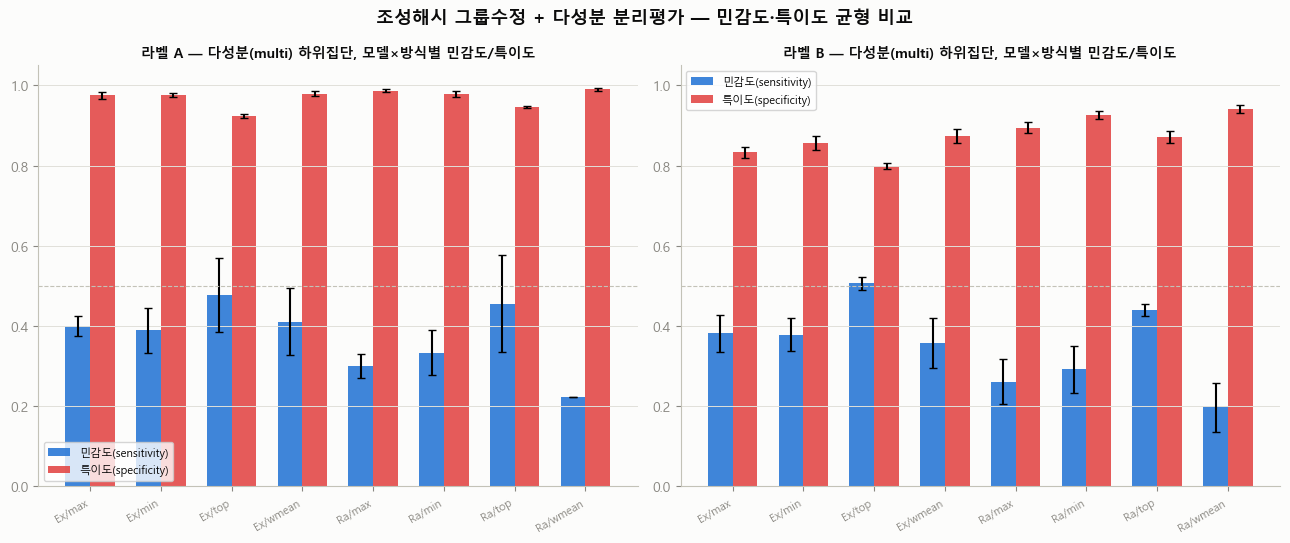

In [7]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

_font_path = r"C:\Windows\Fonts\malgun.ttf"
fm.fontManager.addfont(_font_path)
plt.rcParams["font.family"] = fm.FontProperties(fname=_font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

SURFACE = "#fcfcfb"; INK = "#0b0b0b"; MUTED = "#898781"; GRID_C = "#e1e0d9"; BASE_C = "#c3c2b7"

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), facecolor=SURFACE)
for ax, label_name in zip(axes, ["A", "B"]):
    ax.set_facecolor(SURFACE)
    sub = final_table[(final_table.label == label_name) & (final_table.subgroup == "multi")].copy()
    sub["combo"] = sub["model"].str[:2] + "/" + sub["method"]
    sub = sub.sort_values(["model", "method"])
    x = np.arange(len(sub))
    w = 0.35
    ax.bar(x - w / 2, sub["sensitivity_mean"], width=w, yerr=sub["sensitivity_std"], capsize=3,
           label="민감도(sensitivity)", color="#2a78d6", alpha=0.9)
    ax.bar(x + w / 2, sub["specificity_mean"], width=w, yerr=sub["specificity_std"], capsize=3,
           label="특이도(specificity)", color="#e34948", alpha=0.9)
    ax.set_xticks(x)
    ax.set_xticklabels(sub["combo"], rotation=30, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.axhline(0.5, color=BASE_C, linewidth=0.8, linestyle="--")
    ax.set_title(f"라벨 {label_name} — 다성분(multi) 하위집단, 모델×방식별 민감도/특이도", fontsize=10, color=INK, fontweight="bold")
    ax.legend(fontsize=8)
    ax.tick_params(colors=MUTED)
    for s_ in ["top", "right"]:
        ax.spines[s_].set_visible(False)
    ax.spines["left"].set_color(BASE_C)
    ax.spines["bottom"].set_color(BASE_C)
    ax.grid(axis="y", color=GRID_C, linewidth=0.7, zorder=0)

fig.suptitle("조성해시 그룹수정 + 다성분 분리평가 — 민감도·특이도 균형 비교", fontsize=13, color=INK, fontweight="bold")
plt.tight_layout()
plt.savefig(rf"{BASE}\skin_final_combined_sens_spec.png", dpi=150, facecolor=SURFACE)
plt.show()


## 한계점

1. 민감도·특이도는 재학습 없이 같은 threshold(0.5)로만 비교했습니다 — 실제 배포 시 threshold를 조정하면(예: `skin_threshold_sweep_demo.ipynb` 참고) 균형점이 달라질 수 있습니다.
2. 다성분(multi) 하위집단 표본 수가 전체보다 작아 민감도/특이도 추정치의 변동폭이 overall보다 클 수 있습니다.
3. 조성해시 `comp_group_id`는 "해결된 성분만" 반영하는 근사치입니다(완전한 feature-벡터 해시 기반 그룹핑은 아직 안 함).
4. production 원본 파일은 아직 수정하지 않았습니다 — 이 결과를 최종 채택하려면 원본 `comp_group_id` 교체 여부를 팀에서 결정해야 합니다.
